In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train.csv")

df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (103904, 25)

Column names:
['Unnamed: 0', 'id', 'Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']

Data types:
Unnamed: 0                             int64
id                                     int64
Gender                                object
Customer Type                         object
Age                                    int64
Type of Travel                        object
Class                                 object
Flight Distance                        int64
Inflight wifi service                  int64
Departure/Arrival time convenient      int64
Ease of Online bookin

In [9]:
# Make a copy so the original data stays unchanged
df_clean = df.copy()

# Remove unnecessary columns if they exist
columns_to_drop = ["Unnamed: 0", "id"]

df_clean = df_clean.drop(
    columns=[col for col in columns_to_drop if col in df_clean.columns]
)

print("New dataset shape:", df_clean.shape)
print(df_clean.head())

New dataset shape: (103904, 23)
   Gender      Customer Type  Age   Type of Travel     Class  Flight Distance  \
0    Male     Loyal Customer   13  Personal Travel  Eco Plus              460   
1    Male  disloyal Customer   25  Business travel  Business              235   
2  Female     Loyal Customer   26  Business travel  Business             1142   
3  Female     Loyal Customer   25  Business travel  Business              562   
4    Male     Loyal Customer   61  Business travel  Business              214   

   Inflight wifi service  Departure/Arrival time convenient  \
0                      3                                  4   
1                      3                                  2   
2                      2                                  2   
3                      2                                  5   
4                      3                                  3   

   Ease of Online booking  Gate location  ...  Inflight entertainment  \
0                       3    

In [10]:
missing_values = df_clean.isnull().sum()

print(missing_values[missing_values > 0])

Arrival Delay in Minutes    310
dtype: int64


In [11]:
median_delay = df_clean["Arrival Delay in Minutes"].median()

df_clean["Arrival Delay in Minutes"] = (
    df_clean["Arrival Delay in Minutes"].fillna(median_delay)
)

print("Missing values remaining:")
print(df_clean.isnull().sum().sum())

Missing values remaining:
0


In [12]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 0


In [13]:
df_clean = df_clean.drop_duplicates()

print("Dataset shape after removing duplicates:", df_clean.shape)

Dataset shape after removing duplicates: (103904, 23)


In [14]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding                    1039

In [15]:
# Satisfaction distribution
satisfaction_counts = df_clean["satisfaction"].value_counts()

print(satisfaction_counts)
print("\nPercentage:")
print(df_clean["satisfaction"].value_counts(normalize=True) * 100)

satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

Percentage:
satisfaction
neutral or dissatisfied    56.666731
satisfied                  43.333269
Name: proportion, dtype: float64


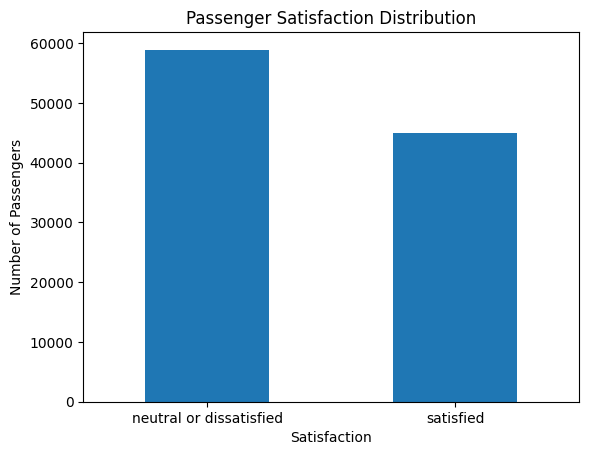

In [16]:
satisfaction_counts.plot(kind="bar")

plt.title("Passenger Satisfaction Distribution")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.show()

In [17]:
class_satisfaction = pd.crosstab(
    df_clean["Class"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(class_satisfaction)

satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                    30.574852  69.425148
Eco                         81.386245  18.613755
Eco Plus                    75.393648  24.606352


In [18]:
class_satisfaction = pd.crosstab(
    df_clean["Class"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(class_satisfaction)

satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                    30.574852  69.425148
Eco                         81.386245  18.613755
Eco Plus                    75.393648  24.606352


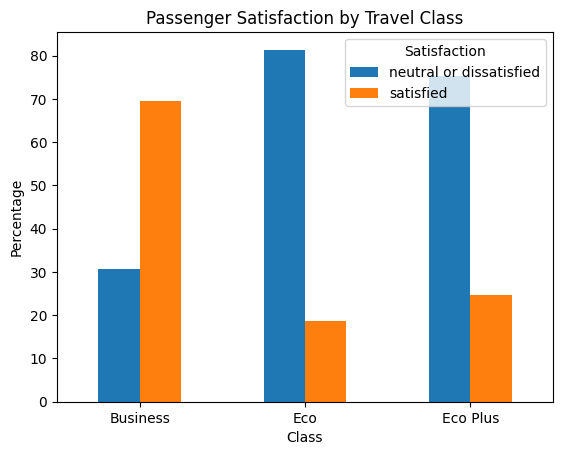

In [19]:
class_satisfaction.plot(kind="bar")

plt.title("Passenger Satisfaction by Travel Class")
plt.xlabel("Class")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()

In [20]:
delay_analysis = df_clean.groupby("satisfaction")[
    ["Departure Delay in Minutes", "Arrival Delay in Minutes"]
].mean()

print(delay_analysis)

                         Departure Delay in Minutes  Arrival Delay in Minutes
satisfaction                                                                 
neutral or dissatisfied                   16.503728                 17.074594
satisfied                                 12.608084                 12.594892


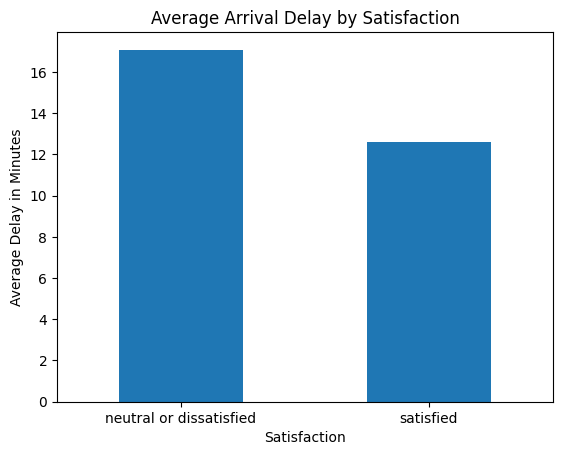

In [21]:
df_clean.groupby("satisfaction")[
    "Arrival Delay in Minutes"
].mean().plot(kind="bar")

plt.title("Average Arrival Delay by Satisfaction")
plt.xlabel("Satisfaction")
plt.ylabel("Average Delay in Minutes")
plt.xticks(rotation=0)
plt.show()

In [22]:
customer_satisfaction = pd.crosstab(
    df_clean["Customer Type"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(customer_satisfaction)

satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                   52.270881  47.729119
disloyal Customer                76.334229  23.665771


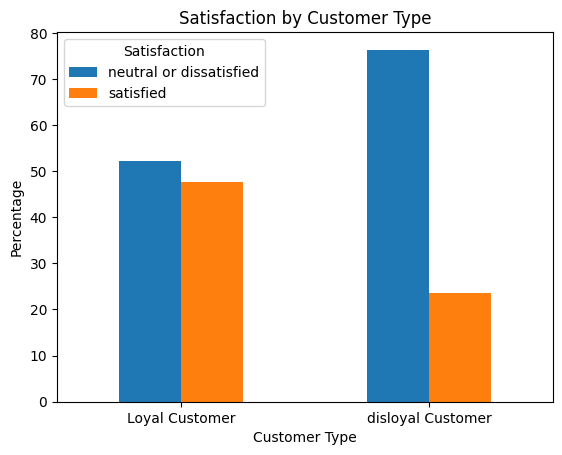

In [23]:
customer_satisfaction.plot(kind="bar")

plt.title("Satisfaction by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()

In [24]:
travel_satisfaction = pd.crosstab(
    df_clean["Type of Travel"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(travel_satisfaction)

satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                41.740283  58.259717
Personal Travel                89.832243  10.167757


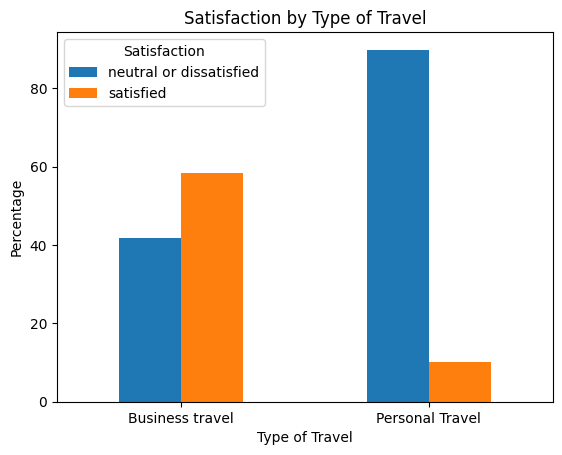

In [25]:
travel_satisfaction.plot(kind="bar")

plt.title("Satisfaction by Type of Travel")
plt.xlabel("Type of Travel")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()

In [26]:
service_columns = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

In [27]:
service_averages = df_clean[service_columns].mean().sort_values(ascending=False)

print(service_averages)

Inflight service                     3.640428
Baggage handling                     3.631833
Seat comfort                         3.439396
On-board service                     3.382363
Inflight entertainment               3.358158
Leg room service                     3.351055
Checkin service                      3.304290
Cleanliness                          3.286351
Online boarding                      3.250375
Food and drink                       3.202129
Departure/Arrival time convenient    3.060296
Gate location                        2.976883
Ease of Online booking               2.756901
Inflight wifi service                2.729683
dtype: float64


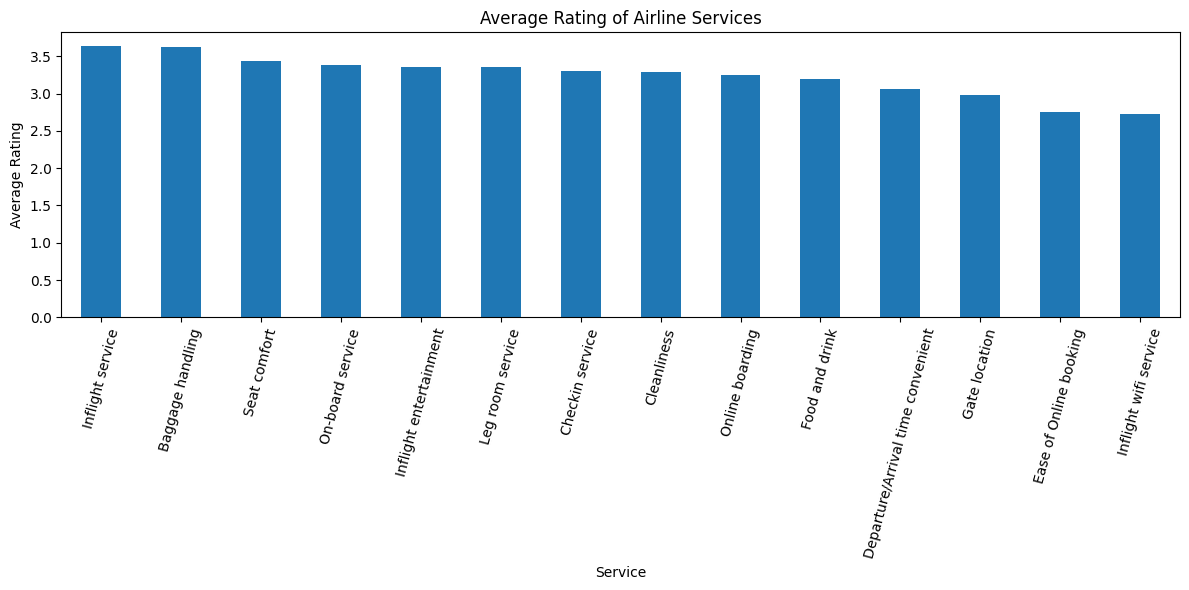

In [28]:
service_averages.plot(kind="bar", figsize=(12, 6))

plt.title("Average Rating of Airline Services")
plt.xlabel("Service")
plt.ylabel("Average Rating")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [29]:
service_by_satisfaction = df_clean.groupby("satisfaction")[service_columns].mean()

print(service_by_satisfaction)

                         Inflight wifi service  \
satisfaction                                     
neutral or dissatisfied               2.399633   
satisfied                             3.161288   

                         Departure/Arrival time convenient  \
satisfaction                                                 
neutral or dissatisfied                           3.129112   
satisfied                                         2.970305   

                         Ease of Online booking  Gate location  \
satisfaction                                                     
neutral or dissatisfied                2.546850       2.976121   
satisfied                              3.031582       2.977879   

                         Food and drink  Online boarding  Seat comfort  \
satisfaction                                                             
neutral or dissatisfied         2.95805         2.656125      3.036295   
satisfied                       3.52131         4.027474      3

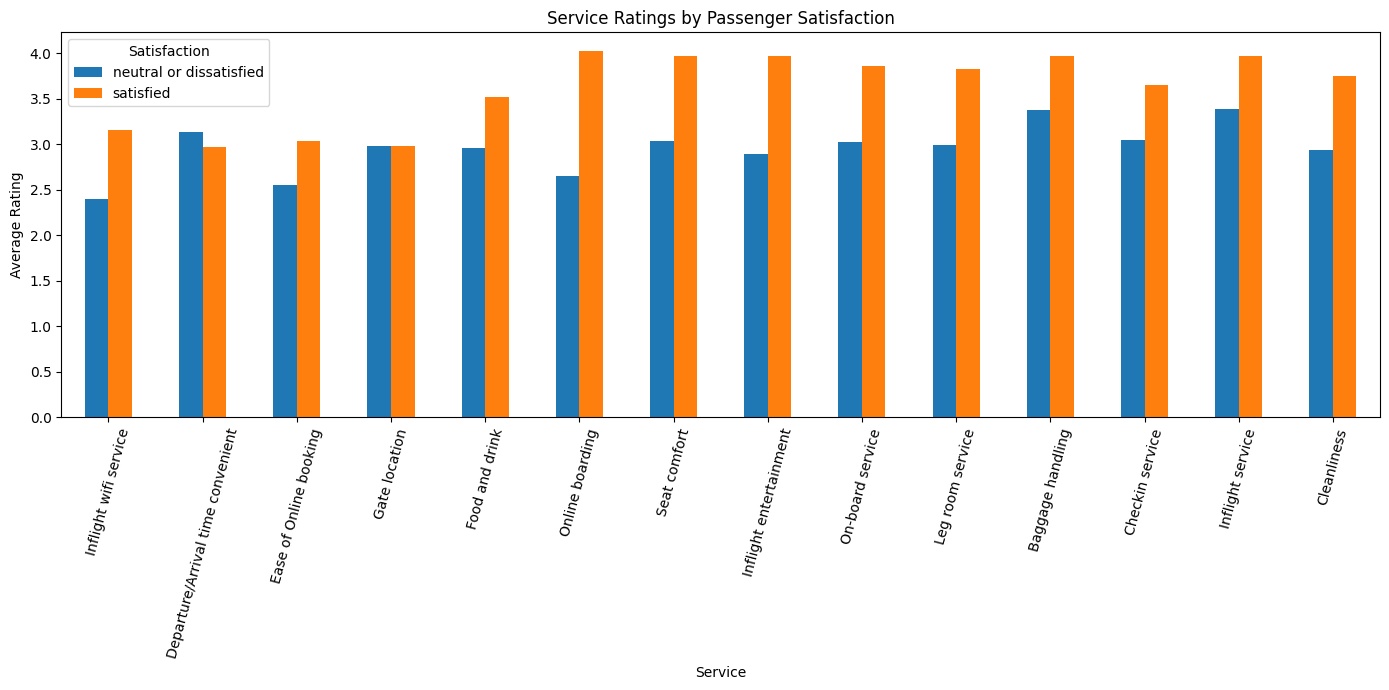

In [30]:
service_by_satisfaction.T.plot(kind="bar", figsize=(14, 7))

plt.title("Service Ratings by Passenger Satisfaction")
plt.xlabel("Service")
plt.ylabel("Average Rating")
plt.xticks(rotation=75)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [31]:
service_gap = (
    service_by_satisfaction.loc["satisfied"]
    - service_by_satisfaction.loc["neutral or dissatisfied"]
).sort_values(ascending=False)

print(service_gap)

Online boarding                      1.371348
Inflight entertainment               1.070775
Seat comfort                         0.930235
On-board service                     0.838166
Leg room service                     0.831332
Cleanliness                          0.808219
Inflight wifi service                0.761655
Checkin service                      0.603089
Baggage handling                     0.590405
Inflight service                     0.580647
Food and drink                       0.563261
Ease of Online booking               0.484732
Gate location                        0.001758
Departure/Arrival time convenient   -0.158807
dtype: float64


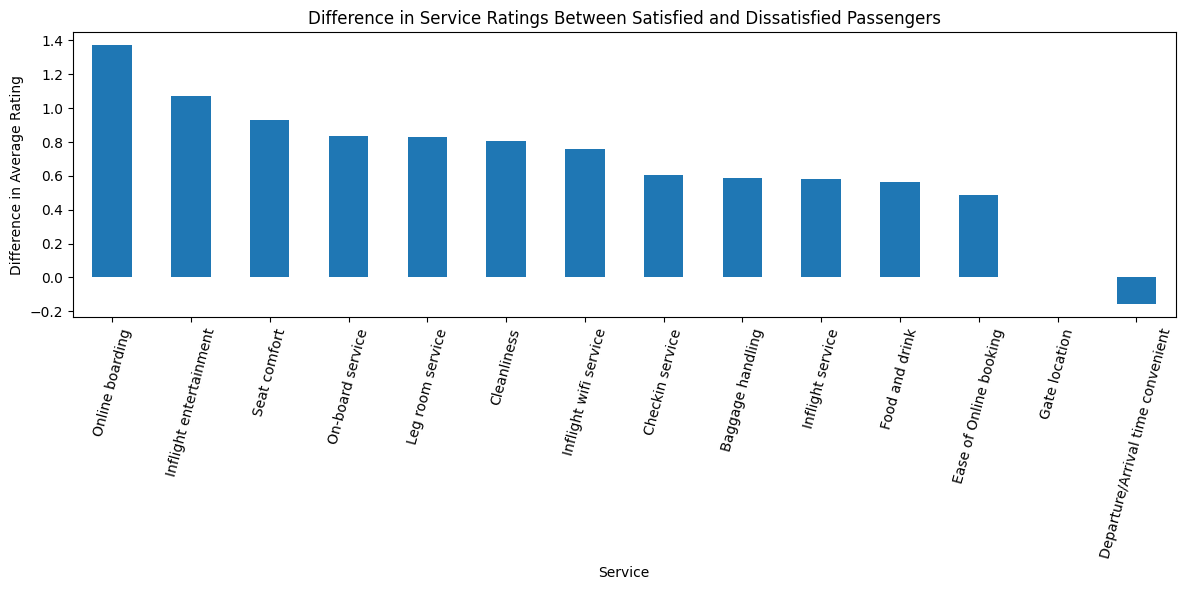

In [32]:
service_gap.plot(kind="bar", figsize=(12, 6))

plt.title("Difference in Service Ratings Between Satisfied and Dissatisfied Passengers")
plt.xlabel("Service")
plt.ylabel("Difference in Average Rating")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [33]:
print("Top 3 Highest Rated Services:")
print(service_averages.head(3))

print("\nTop 3 Lowest Rated Services:")
print(service_averages.tail(3))

Top 3 Highest Rated Services:
Inflight service    3.640428
Baggage handling    3.631833
Seat comfort        3.439396
dtype: float64

Top 3 Lowest Rated Services:
Gate location             2.976883
Ease of Online booking    2.756901
Inflight wifi service     2.729683
dtype: float64


In [34]:
df_clean["satisfaction_numeric"] = df_clean["satisfaction"].map({
    "neutral or dissatisfied": 0,
    "satisfied": 1
})

In [35]:
numeric_df = df_clean.select_dtypes(include=["int64", "float64"])

correlation_matrix = numeric_df.corr()

print(correlation_matrix["satisfaction_numeric"].sort_values(ascending=False))

satisfaction_numeric                 1.000000
Online boarding                      0.503557
Inflight entertainment               0.398059
Seat comfort                         0.349459
On-board service                     0.322383
Leg room service                     0.313131
Cleanliness                          0.305198
Flight Distance                      0.298780
Inflight wifi service                0.284245
Baggage handling                     0.247749
Inflight service                     0.244741
Checkin service                      0.236174
Food and drink                       0.209936
Ease of Online booking               0.171705
Age                                  0.137167
Gate location                        0.000682
Departure Delay in Minutes          -0.050494
Departure/Arrival time convenient   -0.051601
Arrival Delay in Minutes            -0.057435
Name: satisfaction_numeric, dtype: float64


In [36]:
satisfaction_corr = (
    correlation_matrix["satisfaction_numeric"]
    .drop("satisfaction_numeric")
    .sort_values(ascending=False)
)

print(satisfaction_corr)

Online boarding                      0.503557
Inflight entertainment               0.398059
Seat comfort                         0.349459
On-board service                     0.322383
Leg room service                     0.313131
Cleanliness                          0.305198
Flight Distance                      0.298780
Inflight wifi service                0.284245
Baggage handling                     0.247749
Inflight service                     0.244741
Checkin service                      0.236174
Food and drink                       0.209936
Ease of Online booking               0.171705
Age                                  0.137167
Gate location                        0.000682
Departure Delay in Minutes          -0.050494
Departure/Arrival time convenient   -0.051601
Arrival Delay in Minutes            -0.057435
Name: satisfaction_numeric, dtype: float64


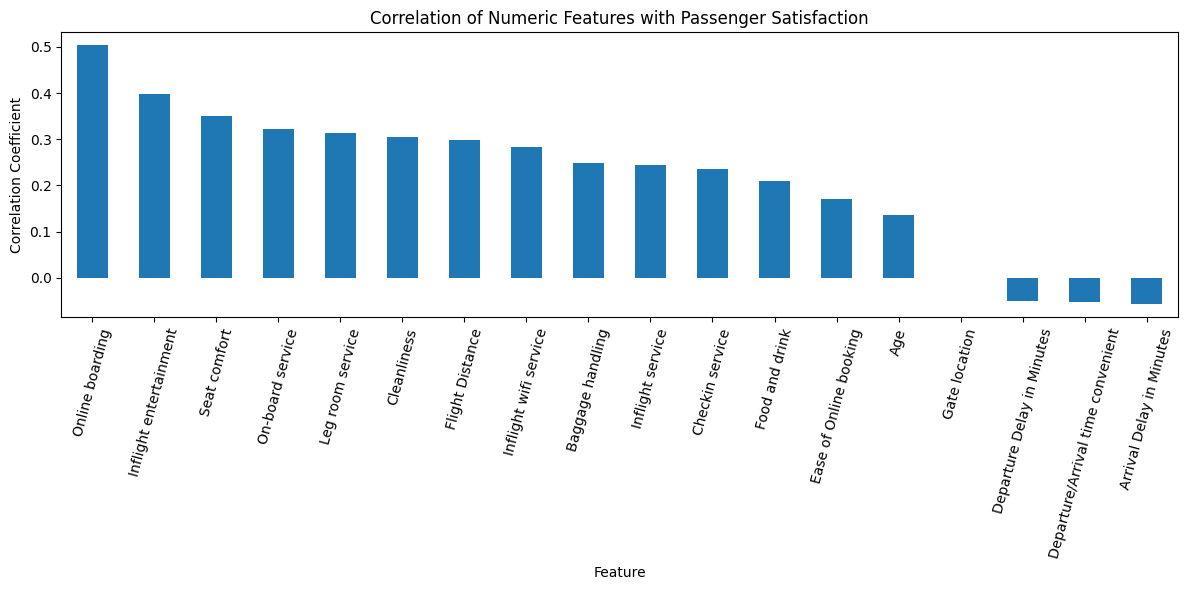

In [37]:
satisfaction_corr.plot(kind="bar", figsize=(12, 6))

plt.title("Correlation of Numeric Features with Passenger Satisfaction")
plt.xlabel("Feature")
plt.ylabel("Correlation Coefficient")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [38]:
print("Top 10 Features Most Related to Satisfaction:")

print(
    satisfaction_corr
    .abs()
    .sort_values(ascending=False)
    .head(10)
)

Top 10 Features Most Related to Satisfaction:
Online boarding           0.503557
Inflight entertainment    0.398059
Seat comfort              0.349459
On-board service          0.322383
Leg room service          0.313131
Cleanliness               0.305198
Flight Distance           0.298780
Inflight wifi service     0.284245
Baggage handling          0.247749
Inflight service          0.244741
Name: satisfaction_numeric, dtype: float64


In [39]:
bins = [0, 18, 30, 45, 60, 100]
labels = ["Under 18", "18-30", "31-45", "46-60", "60+"]

df_clean["Age Group"] = pd.cut(
    df_clean["Age"],
    bins=bins,
    labels=labels
)

In [40]:
age_satisfaction = pd.crosstab(
    df_clean["Age Group"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(age_satisfaction)

satisfaction  neutral or dissatisfied  satisfied
Age Group                                       
Under 18                    82.725334  17.274666
18-30                       64.588225  35.411775
31-45                       51.272104  48.727896
46-60                       42.591664  57.408336
60+                         79.162487  20.837513


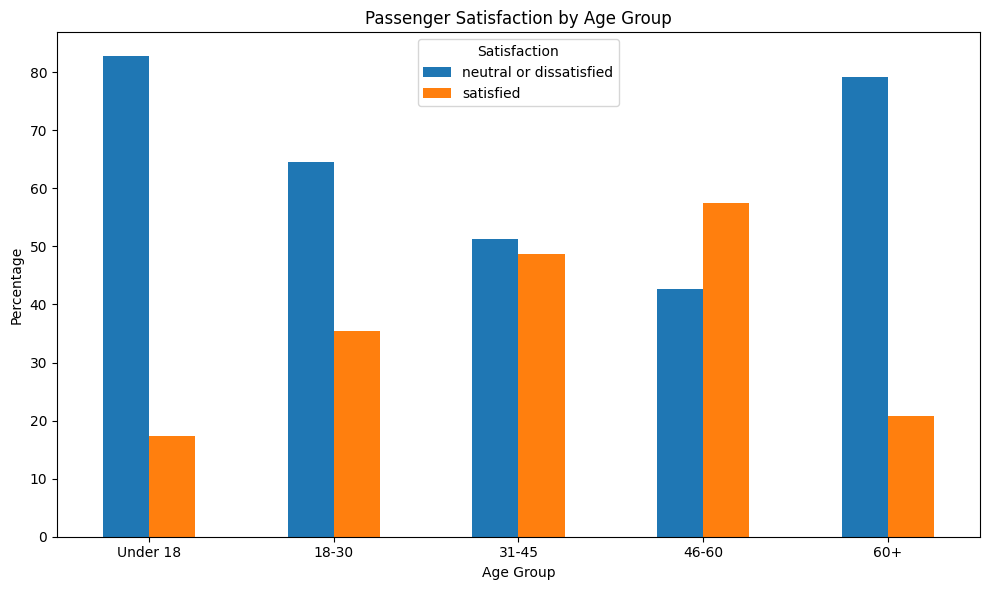

In [41]:
age_satisfaction.plot(kind="bar", figsize=(10, 6))

plt.title("Passenger Satisfaction by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.tight_layout()
plt.show()

In [42]:
gender_satisfaction = pd.crosstab(
    df_clean["Gender"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(gender_satisfaction)

satisfaction  neutral or dissatisfied  satisfied
Gender                                          
Female                      57.262882  42.737118
Male                        56.052524  43.947476


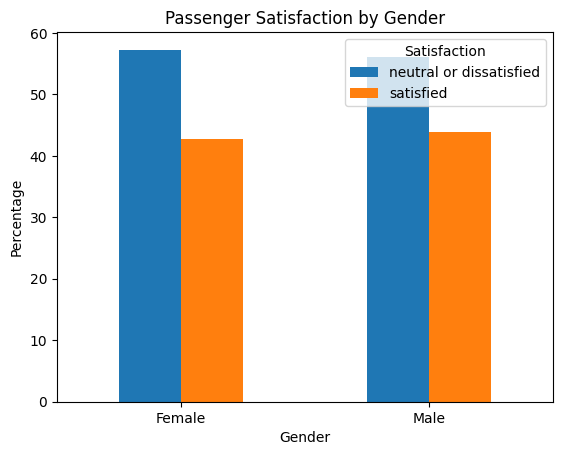

In [43]:
gender_satisfaction.plot(kind="bar")

plt.title("Passenger Satisfaction by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()

In [44]:
class_analysis = pd.crosstab(
    df_clean["Class"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(class_analysis)

satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                    30.574852  69.425148
Eco                         81.386245  18.613755
Eco Plus                    75.393648  24.606352


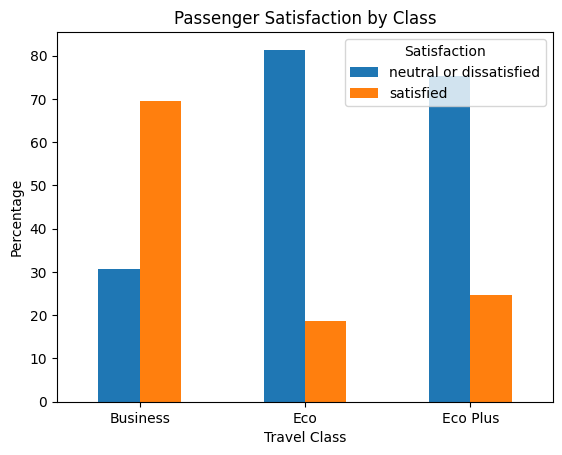

In [45]:
class_analysis.plot(kind="bar")

plt.title("Passenger Satisfaction by Class")
plt.xlabel("Travel Class")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Satisfaction")
plt.show()

In [46]:
customer_analysis = pd.crosstab(
    df_clean["Customer Type"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(customer_analysis)

satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                   52.270881  47.729119
disloyal Customer                76.334229  23.665771


In [47]:
travel_analysis = pd.crosstab(
    df_clean["Type of Travel"],
    df_clean["satisfaction"],
    normalize="index"
) * 100

print(travel_analysis)

satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                41.740283  58.259717
Personal Travel                89.832243  10.167757


In [48]:
segment_summary = df_clean.groupby(
    ["Class", "Type of Travel"]
)["satisfaction_numeric"].mean() * 100

print(segment_summary)

Class     Type of Travel 
Business  Business travel    72.021554
          Personal Travel    12.239221
Eco       Business travel    29.619391
          Personal Travel    10.197070
Eco Plus  Business travel    39.331620
          Personal Travel     8.712542
Name: satisfaction_numeric, dtype: float64


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Remove the original text target
X = df_clean.drop(
    columns=["satisfaction", "satisfaction_numeric"]
)

# Target
y = df_clean["satisfaction_numeric"]

In [50]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numeric features:
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

Categorical features:
['Gender', 'Customer Type', 'Type of Travel', 'Class', 'Age Group']


In [51]:
numeric_transformer = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("onehot", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [52]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000
        ))
    ]
)

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (83123, 23)
Testing data: (20781, 23)


In [54]:
model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


In [55]:
y_pred = model.predict(X_test)

In [56]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy Percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.8770511524950676
Accuracy Percentage: 87.71 %


In [57]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Neutral/Dissatisfied",
            "Satisfied"
        ]
    )
)

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.88      0.90      0.89     11776
           Satisfied       0.87      0.84      0.86      9005

            accuracy                           0.88     20781
           macro avg       0.88      0.87      0.87     20781
        weighted avg       0.88      0.88      0.88     20781



In [58]:
cm = confusion_matrix(y_test, y_pred)

print(cm)

[[10635  1141]
 [ 1414  7591]]


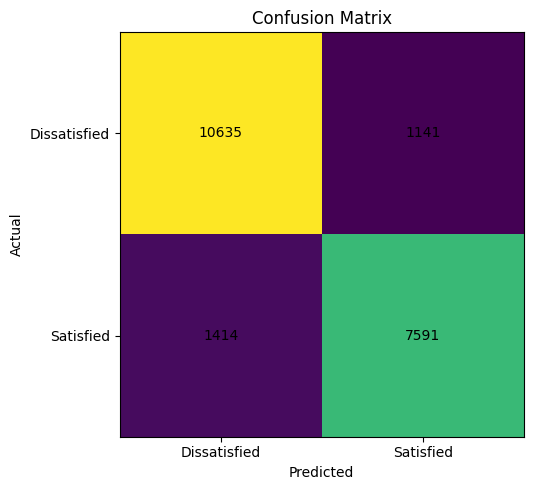

In [59]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Dissatisfied", "Satisfied"]
)

plt.yticks(
    [0, 1],
    ["Dissatisfied", "Satisfied"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [61]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [62]:
rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [63]:
rf_pred = rf_model.predict(X_test)

In [64]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)
print("Random Forest Accuracy Percentage:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 0.9629950435493961
Random Forest Accuracy Percentage: 96.3 %


In [65]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Neutral/Dissatisfied",
            "Satisfied"
        ]
    )
)

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.96      0.98      0.97     11776
           Satisfied       0.97      0.95      0.96      9005

            accuracy                           0.96     20781
           macro avg       0.96      0.96      0.96     20781
        weighted avg       0.96      0.96      0.96     20781



In [66]:
print(
    classification_report(
        y_test,
        rf_pred,
        target_names=[
            "Neutral/Dissatisfied",
            "Satisfied"
        ]
    )
)

                      precision    recall  f1-score   support

Neutral/Dissatisfied       0.96      0.98      0.97     11776
           Satisfied       0.97      0.95      0.96      9005

            accuracy                           0.96     20781
           macro avg       0.96      0.96      0.96     20781
        weighted avg       0.96      0.96      0.96     20781



In [67]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ]
})

model_comparison["Accuracy (%)"] = (
    model_comparison["Accuracy"] * 100
).round(2)

print(model_comparison)

                 Model  Accuracy  Accuracy (%)
0  Logistic Regression  0.877051         87.71
1        Random Forest  0.962995         96.30


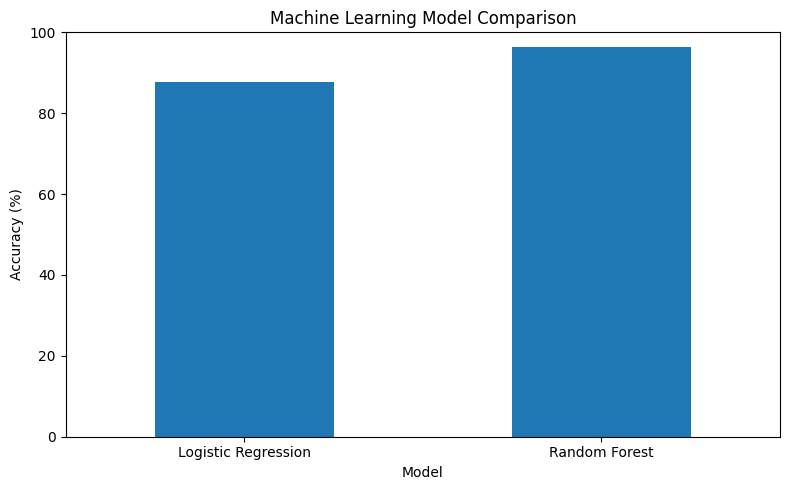

In [68]:
model_comparison.plot(
    x="Model",
    y="Accuracy (%)",
    kind="bar",
    legend=False,
    figsize=(8, 5)
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [69]:
rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

[[11501   275]
 [  494  8511]]


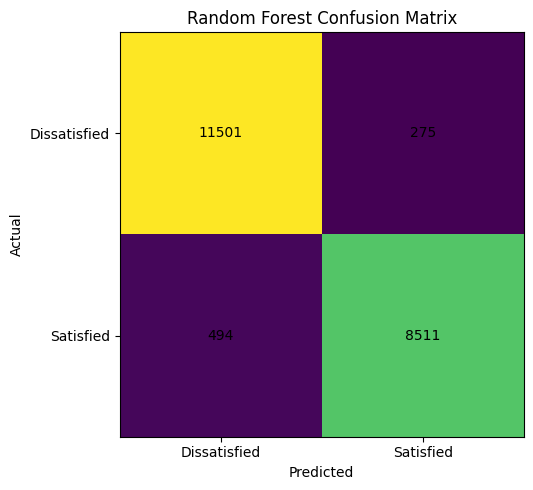

In [70]:
plt.figure(figsize=(6, 5))

plt.imshow(rf_cm)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Dissatisfied", "Satisfied"]
)

plt.yticks(
    [0, 1],
    ["Dissatisfied", "Satisfied"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            rf_cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [71]:
# Get the trained Random Forest model
rf_classifier = rf_model.named_steps["classifier"]

# Get transformed feature names
feature_names = rf_model.named_steps["preprocessor"].get_feature_names_out()

# Get feature importance values
importances = rf_classifier.feature_importances_

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(20))

                                   Feature  Importance
7                     num__Online boarding    0.137821
2               num__Inflight wifi service    0.133893
24                     cat__Class_Business    0.069137
9              num__Inflight entertainment    0.058243
22     cat__Type of Travel_Business travel    0.057375
23     cat__Type of Travel_Personal Travel    0.056360
8                        num__Seat comfort    0.045464
25                          cat__Class_Eco    0.043884
4              num__Ease of Online booking    0.038160
11                   num__Leg room service    0.034806
21    cat__Customer Type_disloyal Customer    0.031584
1                     num__Flight Distance    0.031373
12                   num__Baggage handling    0.027036
0                                 num__Age    0.026487
13                    num__Checkin service    0.025910
15                        num__Cleanliness    0.025619
10                   num__On-board service    0.025191
14        

In [72]:
feature_importance_df["Feature"] = (
    feature_importance_df["Feature"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

print(feature_importance_df.head(20))

                              Feature  Importance
7                     Online boarding    0.137821
2               Inflight wifi service    0.133893
24                     Class_Business    0.069137
9              Inflight entertainment    0.058243
22     Type of Travel_Business travel    0.057375
23     Type of Travel_Personal Travel    0.056360
8                        Seat comfort    0.045464
25                          Class_Eco    0.043884
4              Ease of Online booking    0.038160
11                   Leg room service    0.034806
21    Customer Type_disloyal Customer    0.031584
1                     Flight Distance    0.031373
12                   Baggage handling    0.027036
0                                 Age    0.026487
13                    Checkin service    0.025910
15                        Cleanliness    0.025619
10                   On-board service    0.025191
14                   Inflight service    0.025091
20       Customer Type_Loyal Customer    0.023211


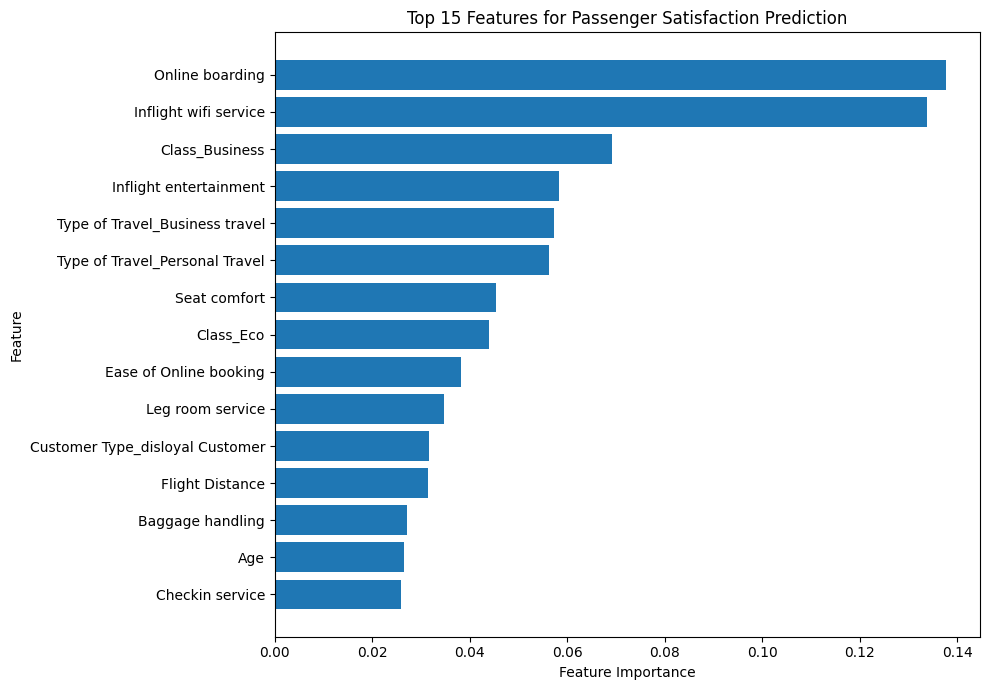

In [73]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 15 Features for Passenger Satisfaction Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

In [74]:
print("Top 10 Most Important Features:")

print(
    feature_importance_df[
        ["Feature", "Importance"]
    ].head(10)
)

Top 10 Most Important Features:
                           Feature  Importance
7                  Online boarding    0.137821
2            Inflight wifi service    0.133893
24                  Class_Business    0.069137
9           Inflight entertainment    0.058243
22  Type of Travel_Business travel    0.057375
23  Type of Travel_Personal Travel    0.056360
8                     Seat comfort    0.045464
25                       Class_Eco    0.043884
4           Ease of Online booking    0.038160
11                Leg room service    0.034806


In [75]:
feature_importance_df.to_csv(
    "feature_importance.csv",
    index=False
)

print("Feature importance file saved.")

Feature importance file saved.


In [76]:
print("=== SATISFACTION RATE ===")
print(
    (df_clean["satisfaction_numeric"].mean() * 100).round(2),
    "%"
)

print("\n=== SATISFACTION BY CLASS ===")
print(
    df_clean.groupby("Class")["satisfaction_numeric"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\n=== SATISFACTION BY CUSTOMER TYPE ===")
print(
    df_clean.groupby("Customer Type")["satisfaction_numeric"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\n=== SATISFACTION BY TRAVEL PURPOSE ===")
print(
    df_clean.groupby("Type of Travel")["satisfaction_numeric"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("\n=== AVERAGE DELAYS BY SATISFACTION ===")
print(
    df_clean.groupby("satisfaction")[
        ["Departure Delay in Minutes",
         "Arrival Delay in Minutes"]
    ].mean().round(2)
)

print("\n=== TOP SERVICE RATING DIFFERENCES ===")
print(service_gap.head(10).round(2))

print("\n=== TOP RANDOM FOREST FEATURES ===")
print(
    feature_importance_df[
        ["Feature", "Importance"]
    ].head(10)
)

=== SATISFACTION RATE ===
43.33 %

=== SATISFACTION BY CLASS ===
Class
Business    69.43
Eco Plus    24.61
Eco         18.61
Name: satisfaction_numeric, dtype: float64

=== SATISFACTION BY CUSTOMER TYPE ===
Customer Type
Loyal Customer       47.73
disloyal Customer    23.67
Name: satisfaction_numeric, dtype: float64

=== SATISFACTION BY TRAVEL PURPOSE ===
Type of Travel
Business travel    58.26
Personal Travel    10.17
Name: satisfaction_numeric, dtype: float64

=== AVERAGE DELAYS BY SATISFACTION ===
                         Departure Delay in Minutes  Arrival Delay in Minutes
satisfaction                                                                 
neutral or dissatisfied                       16.50                     17.07
satisfied                                     12.61                     12.59

=== TOP SERVICE RATING DIFFERENCES ===
Online boarding           1.37
Inflight entertainment    1.07
Seat comfort              0.93
On-board service          0.84
Leg room service  

In [77]:
summary = pd.DataFrame({
    "Metric": [
        "Overall Satisfaction Rate",
        "Logistic Regression Accuracy",
        "Random Forest Accuracy"
    ],
    "Value": [
        f"{df_clean['satisfaction_numeric'].mean()*100:.2f}%",
        f"{accuracy*100:.2f}%",
        f"{rf_accuracy*100:.2f}%"
    ]
})

summary

,Metric,Value
0,Overall Satisfaction Rate,43.33%
1,Logistic Regression Accuracy,87.71%
2,Random Forest Accuracy,96.30%


In [78]:
df_clean.to_csv(
    "airline_passenger_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
